In [15]:
from langchain_ollama import ChatOllama
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser


## Chain with custom runnable

In [16]:
# TASK 1- prompt 
prompt_template = ChatPromptTemplate.from_messages([
    ('system', 'Bạn là 1 chuyên gia'),
    ('human', '{message}')
])

In [17]:
# TASK 2 - LLM
llm = ChatOllama(model = 'llama3.2:3b', temperature=0)

In [18]:
# TASK 3 - OUTPUT PARSER
from langchain_core.output_parsers import StrOutputParser
str_parser = StrOutputParser()

In [19]:
# TASK 4 - [custom runnable]
from langchain_core.runnables import RunnableLambda
def dictionary_marker(text:str) -> dict:
    return {'text': text}
dictionary_marker_runnable = RunnableLambda(dictionary_marker)

In [20]:
# TASK 5 [Template for post]
prompt_post = ChatPromptTemplate.from_messages(
    messages = [
        ('system', 'bạn là 1 chuyên gia về IT'),
        ('human', 'hãy nói cho tôi về {text}')
    ]
)

In [21]:
# TASK 6 [generate the post]
llm = ChatOllamallm_ollama = ChatOllama(model = 'llama3.2:3b', temperature=0)

In [22]:
# Task 7 [str parser]
str_parser = StrOutputParser()

In [23]:
chain = prompt_template | llm | str_parser | dictionary_marker_runnable | prompt_post | llm | str_parser

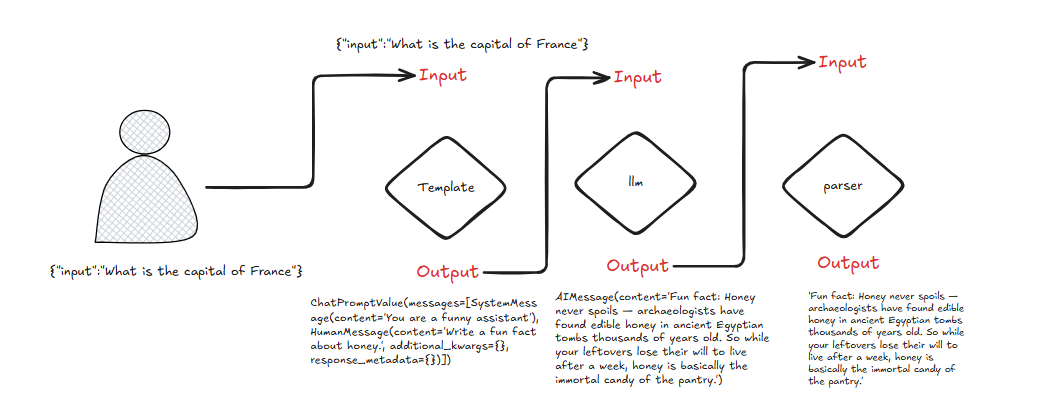

Input (Tin nhắn ban đầu) 
  --> [prompt_template] 
  --> [llm] 
  --> [str_parser] 
  --> [dictionary_marker_runnable] 
  --> [prompt_post] 
  --> [llm] 
  --> [str_parser] 
  --> Final Output

In [24]:
chain.invoke({"message": "Hãy gợi ý tên một món ăn truyền thống của Việt Nam."})

'Bún Riêu là một món ăn truyền thống và dân dã của Việt Nam, được yêu thích bởi nhiều người ở miền Nam. Món ăn này không chỉ có vị ngọt, đậm đà mà còn rất tốt cho sức khỏe do chứa nhiều protein, vitamin, và khoáng chất từ các nguyên liệu chính như cá hồi, tôm, và rau sống.\n\nBún Riêu là một món ăn truyền thống của người Việt Nam, đặc biệt là ở các tỉnh như Bình Thuận, Bình Định, và Phú Yên. Món ăn này thường được phục vụ với bún tươi, riêu nóng, và các loại rau sống như rau muống, rau xà lách, và rau mùi.\n\nMột số nguyên liệu chính của Bún Riêu bao gồm:\n\n* Bún: là nguyên liệu chính của món ăn, thường được sử dụng là bún tươi hoặc bún khô.\n* Riêu: là phần chính của món ăn, được làm từ cá hồi nấu với tôm, ớt, hành, tỏi, và các gia vị khác.\n* Tôm: được sử dụng để tăng cường protein và hương vị cho món ăn.\n* Ớt: được sử dụng để tăng cường hương vị và độ cay cho món ăn.\n* Hành, tỏi: được sử dụng để tăng cường hương vị và độ thơm cho món ăn.\n* Rau sống: như rau muống, rau xà lách, v

In [26]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama

# 1. Khởi tạo Prompt Template và LLM
prompt_template = ChatPromptTemplate.from_messages([
    ('human', 'Hãy nói cho tôi 1 chủ đề thú vị.')
])

llm = ChatOllama(model='llama3.2:3b', temperature=0)

# 2. Tạo một chain đơn giản chỉ gồm Prompt và LLM (Không có str_parser)
chain = prompt_template | llm

# 3. Thực thi chain
result = chain.invoke({})

# 4. Kiểm tra kiểu dữ liệu và nội dung bên trong của AIMessage
print("Kiểu dữ liệu của kết quả (type):", type(result))
print("-" * 40)
print("In toàn bộ đối tượng AIMessage:", result)
print("-" * 40)
print("Nội dung văn bản bên trong (.content):", result.content)

Kiểu dữ liệu của kết quả (type): <class 'langchain_core.messages.ai.AIMessage'>
----------------------------------------
In toàn bộ đối tượng AIMessage: content='Chủ đề thú vị mà tôi muốn giới thiệu cho bạn là "Thế giới bí mật của các loài động vật có vú".\n\nBạn biết không, có rất nhiều loài động vật có vú trên thế giới mà chúng ta chưa khám phá được hết về hành vi, sinh thái và đặc điểm của chúng. Ví dụ, loài động vật có vú duy nhất sống sót trong đại dương là động vật có vú biển (cá voi), nhưng chúng ta vẫn chưa khám phá được hết về hành vi và sinh thái của chúng.\n\nMột chủ đề thú vị khác là "Thế giới bí mật của các loài động vật có vú trong rừng". Rừng là nơi sinh sống của nhiều loài động vật có vú, nhưng chúng ta vẫn chưa khám phá được hết về hành vi và sinh thái của chúng. Ví dụ, loài động vật có vú này có thể sống sót trong rừng sâu, nhưng chúng ta vẫn chưa biết về hành vi và sinh thái của chúng.\n\nHoặc, bạn có thể quan tâm đến chủ đề "Thế giới bí mật của các loài động vật có 